In [2]:
%pip install plotly pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [6]:
import seaborn as sns

In [7]:
import plotly.express as px

### Set default visualization style

In [8]:
sns.set_theme(style="whitegrid")

In [9]:
df = pd.read_csv("ecommerce_customers.csv")

In [10]:
df.head()

,Customer_ID,Age,Gender,Product_Category,Purchase_Amount,Transaction_Date,Customer_Tenure,Loyalty_Status
0,1103,74.0,Male,Clothing,104.49,2026-06-14,4,Bronze
1,1180,45.0,Male,Electronics,318.44,2026-04-16,3,Bronze
2,1093,66.0,Male,Clothing,24.18,2026-06-08,2,Bronze
3,1015,35.0,Male,Home,16.25,2026-04-13,6,Bronze
4,1107,43.0,Female,Clothing,68.07,2026-09-09,28,Silver


### SECTIOON THREE

In [11]:
print("Dataset dimensions (rows, columns):", df.shape)

Dataset dimensions (rows, columns): (500, 8)


In [12]:
print("\nColumn information:")
print(df.info())


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       500 non-null    int64  
 1   Age               498 non-null    float64
 2   Gender            500 non-null    str    
 3   Product_Category  500 non-null    str    
 4   Purchase_Amount   499 non-null    float64
 5   Transaction_Date  500 non-null    str    
 6   Customer_Tenure   500 non-null    int64  
 7   Loyalty_Status    500 non-null    str    
dtypes: float64(2), int64(2), str(4)
memory usage: 31.4 KB
None


### Inspecting the column names as it brought an error

In [13]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Customer_ID         0
Age                 2
Gender              0
Product_Category    0
Purchase_Amount     1
Transaction_Date    0
Customer_Tenure     0
Loyalty_Status      0
dtype: int64


In [14]:
print("\nStatistical summary:")
print(df.describe())


Statistical summary:
       Customer_ID         Age  Purchase_Amount  Customer_Tenure
count   500.000000  498.000000       499.000000       500.000000
mean   1102.448000   42.497992       185.843868        11.488000
std      57.114301   14.953213       182.079222        11.780808
min    1001.000000   18.000000        10.000000         1.000000
25%    1052.750000   31.000000        74.155000         3.000000
50%    1104.000000   42.000000       120.840000         7.500000
75%    1150.000000   54.000000       256.510000        16.250000
max    1200.000000   75.000000      2056.170000        60.000000


### SECTION FOUR 

In [15]:
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

Number of duplicate rows: 0


In [16]:
df_clean = df.drop_duplicates().copy()

### Handle missing values 

In [17]:
age_median = df_clean['Age'].median()

In [18]:
df_clean['Age'] = df_clean['Age'].fillna(age_median)

In [19]:
purchase_median = df_clean['Purchase_Amount'].median()

In [20]:
df_clean['Purchase_Amount'] = df_clean['Purchase_Amount'].fillna(purchase_median)

### IDENTIFY AND HANDLE OUTLIERS 

In [21]:
for col in ['Age', 'Purchase_Amount', 'Customer_Tenure']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    print(f"Outliers in {col}: {len(outliers)} rows (Upper threshold: {upper_bound:.2f})")

Outliers in Age: 0 rows (Upper threshold: 88.50)
Outliers in Purchase_Amount: 19 rows (Upper threshold: 529.39)
Outliers in Customer_Tenure: 23 rows (Upper threshold: 36.12)


### VERIFY THE DATA IS CLEAN

In [22]:
print(f"Duplicates remaining: {df_clean.duplicated().sum()}")
print(f"Missing values remaining:\n{df_clean.isnull().sum()}")
print(f"Final dataset shape (rows, columns): {df_clean.shape}")

Duplicates remaining: 0
Missing values remaining:
Customer_ID         0
Age                 0
Gender              0
Product_Category    0
Purchase_Amount     0
Transaction_Date    0
Customer_Tenure     0
Loyalty_Status      0
dtype: int64
Final dataset shape (rows, columns): (500, 8)


### DATA ANALYSIS AND VISUALIZATION

Customer Age Statistics:
Mean: 42.50
Median: 42.00
Min: 18.00
Max: 75.00
Std Dev: 14.92


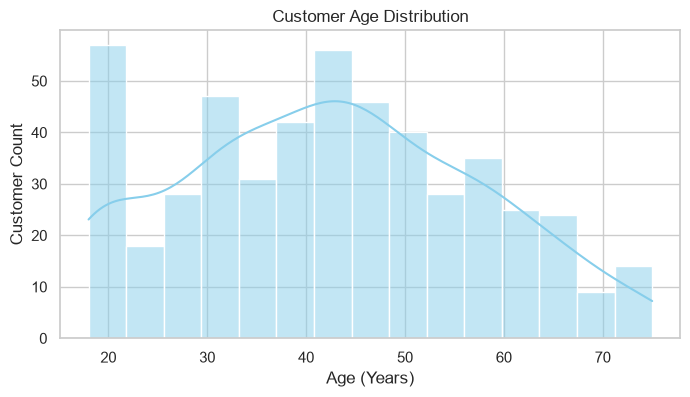

In [23]:
print("Customer Age Statistics:")
print(f"Mean: {df_clean['Age'].mean():.2f}")
print(f"Median: {df_clean['Age'].median():.2f}")
print(f"Min: {df_clean['Age'].min():.2f}")
print(f"Max: {df_clean['Age'].max():.2f}")
print(f"Std Dev: {df_clean['Age'].std():.2f}")

plt.figure(figsize=(8, 4))
sns.histplot(df_clean['Age'], kde=True, color='skyblue', bins=15)
plt.title("Customer Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Customer Count")
plt.show()

### PURCHASE AMOUNT DISTRIBUTION

Purchase Amount Statistics:
Mean: $185.71
Median: $120.84
Min: $10.00
Max: $2056.17
Std Dev: $181.92


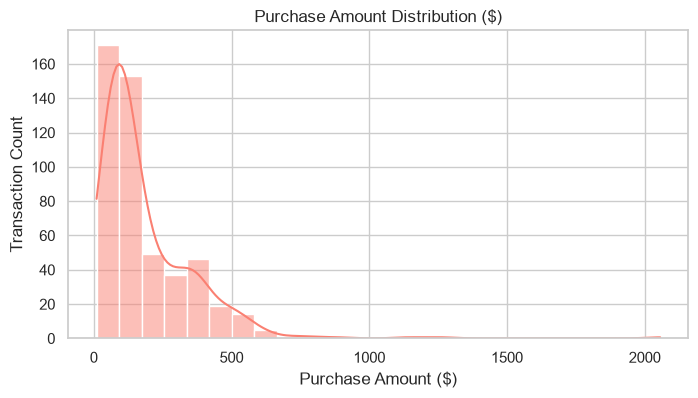

In [24]:
print("Purchase Amount Statistics:")
print(f"Mean: ${df_clean['Purchase_Amount'].mean():.2f}")
print(f"Median: ${df_clean['Purchase_Amount'].median():.2f}")
print(f"Min: ${df_clean['Purchase_Amount'].min():.2f}")
print(f"Max: ${df_clean['Purchase_Amount'].max():.2f}")
print(f"Std Dev: ${df_clean['Purchase_Amount'].std():.2f}")


plt.figure(figsize=(8, 4))
sns.histplot(df_clean['Purchase_Amount'], kde=True, color='salmon', bins=25)
plt.title("Purchase Amount Distribution ($)")
plt.xlabel("Purchase Amount ($)")
plt.ylabel("Transaction Count")
plt.show()

### PRODUCTION CATEGORY PREFERENCES

Purchases by Product Category:
Product_Category
Clothing       108
Sports         107
Beauty         106
Electronics     98
Home            81
Name: count, dtype: int64


C:\Users\emily\AppData\Local\Temp\ipykernel_30632\2932335296.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Product_Category', palette='viridis', order=df_clean['Product_Category'].value_counts().index)


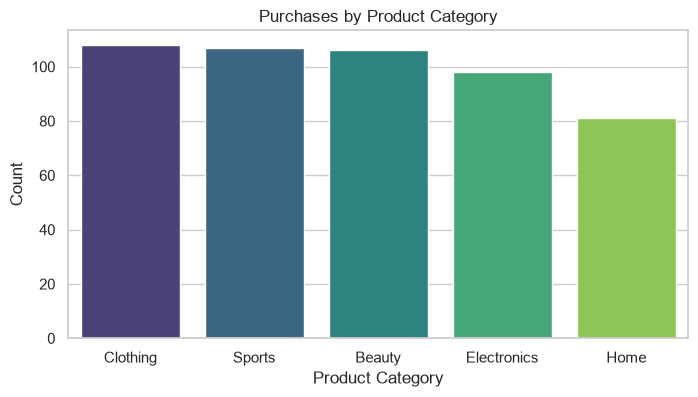

In [25]:
print("Purchases by Product Category:")
print(df_clean['Product_Category'].value_counts())


plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='Product_Category', palette='viridis', order=df_clean['Product_Category'].value_counts().index)
plt.title("Purchases by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Count")
plt.show()

### LOYALTY STATUS DISTRIBUTION

Customers by Loyalty Status:
Loyalty_Status
Bronze    313
Silver    135
Gold       52
Name: count, dtype: int64


C:\Users\emily\AppData\Local\Temp\ipykernel_30632\2075490359.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Loyalty_Status', palette='Blues_r', order=['Bronze', 'Silver', 'Gold'])


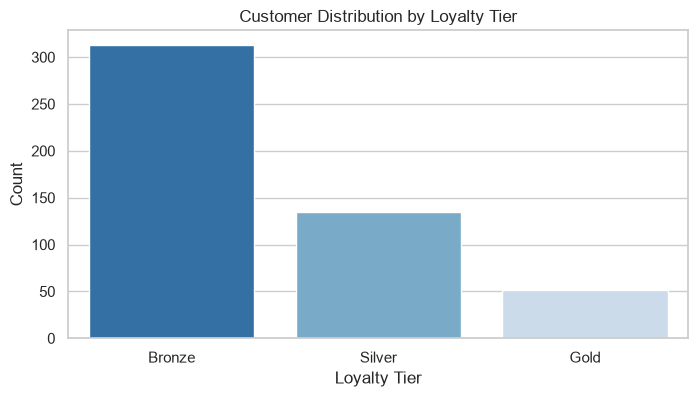

In [27]:
print("Customers by Loyalty Status:")
print(df_clean['Loyalty_Status'].value_counts())


plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='Loyalty_Status', palette='Blues_r', order=['Bronze', 'Silver', 'Gold'])
plt.title("Customer Distribution by Loyalty Tier")
plt.xlabel("Loyalty Tier")
plt.ylabel("Count")
plt.show()

### BIVARIATE ANALYSIS

Correlation between Age and Purchase Amount: 0.0678


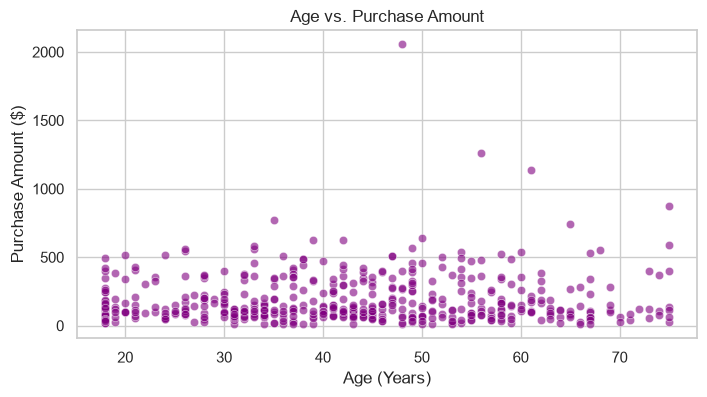

In [28]:
corr = df_clean['Age'].corr(df_clean['Purchase_Amount'])
print(f"Correlation between Age and Purchase Amount: {corr:.4f}")


plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_clean, x='Age', y='Purchase_Amount', alpha=0.6, color='purple')
plt.title("Age vs. Purchase Amount")
plt.xlabel("Age (Years)")
plt.ylabel("Purchase Amount ($)")
plt.show()

### Loyalty Status against Purchase Amount

Spending Statistics by Loyalty Status:
                      mean   median         std  count
Loyalty_Status                                        
Bronze          177.692300  120.840  158.075530    313
Gold            189.681154  119.265  162.700448     52
Silver          202.783852  120.840  233.528703    135


C:\Users\emily\AppData\Local\Temp\ipykernel_30632\3575446705.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Loyalty_Status', y='Purchase_Amount', order=['Bronze', 'Silver', 'Gold'], palette='Set2')


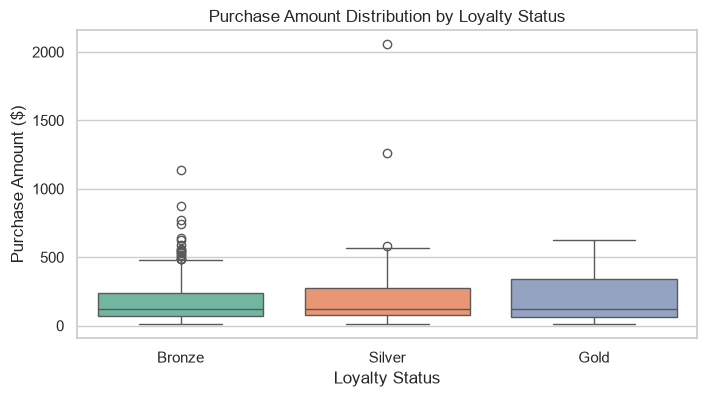

In [29]:
print("Spending Statistics by Loyalty Status:")
print(df_clean.groupby('Loyalty_Status')['Purchase_Amount'].agg(['mean', 'median', 'std', 'count']))


plt.figure(figsize=(8, 4))
sns.boxplot(data=df_clean, x='Loyalty_Status', y='Purchase_Amount', order=['Bronze', 'Silver', 'Gold'], palette='Set2')
plt.title("Purchase Amount Distribution by Loyalty Status")
plt.xlabel("Loyalty Status")
plt.ylabel("Purchase Amount ($)")
plt.show()

### Product Category against Purchase Amount

Spending Statistics by Product Category:
                        mean   median         std  count
Product_Category                                        
Beauty             69.062642   64.340   49.695880    106
Clothing           99.717870   99.575   47.534238    108
Electronics       371.221327  357.535  254.623206     98
Home              279.506543  273.870  161.548544     81
Sports            147.168598  123.350  104.227377    107


C:\Users\emily\AppData\Local\Temp\ipykernel_30632\2388492146.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='Product_Category', y='Purchase_Amount', palette='magma', errorbar=None)


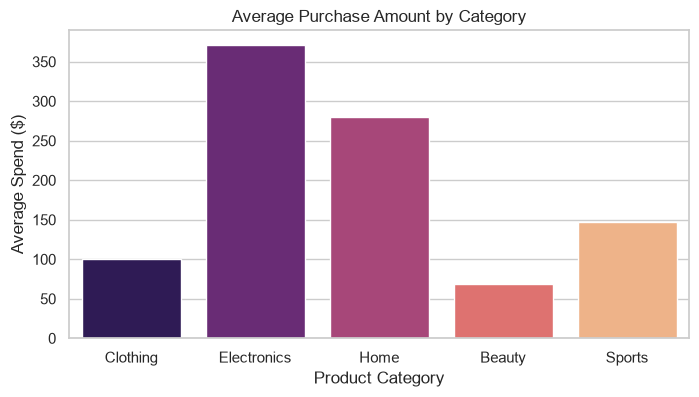

In [30]:

print("Spending Statistics by Product Category:")
print(df_clean.groupby('Product_Category')['Purchase_Amount'].agg(['mean', 'median', 'std', 'count']))


plt.figure(figsize=(8, 4))
sns.barplot(data=df_clean, x='Product_Category', y='Purchase_Amount', palette='magma', errorbar=None)
plt.title("Average Purchase Amount by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Spend ($)")
plt.show()

### Gender against Product Category

Product Category Preferences by Gender:
Product_Category  Beauty  Clothing  Electronics  Home  Sports
Gender                                                       
Female                55        45           49    39      38
Male                  51        63           49    42      69


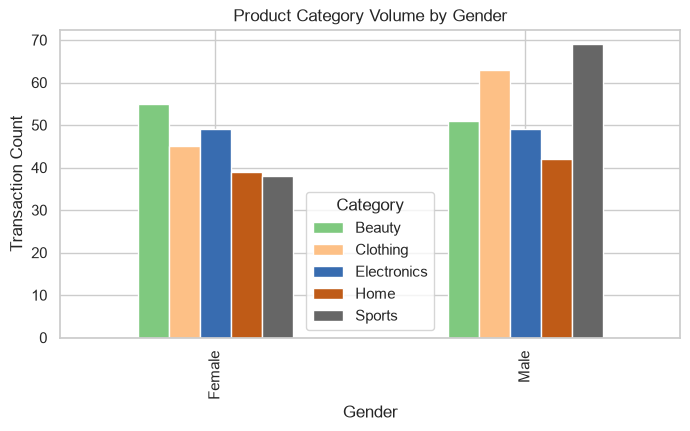

In [31]:
crosstab_gender = pd.crosstab(df_clean['Gender'], df_clean['Product_Category'])
print("Product Category Preferences by Gender:")
print(crosstab_gender)


crosstab_gender.plot(kind='bar', figsize=(8, 4), colormap='Accent')
plt.title("Product Category Volume by Gender")
plt.xlabel("Gender")
plt.ylabel("Transaction Count")
plt.legend(title="Category")
plt.show()

### MULTIVARIATE ANALYSIS

Average Spending by Loyalty Status and Gender:
                             mean   median  count
Loyalty_Status Gender                            
Bronze         Female  180.892463  116.425    134
               Male    175.296648  122.580    179
Gold           Female  183.771515  105.410     33
               Male    199.945263  146.060     19
Silver         Female  173.868983  118.860     59
               Male    225.230921  120.945     76


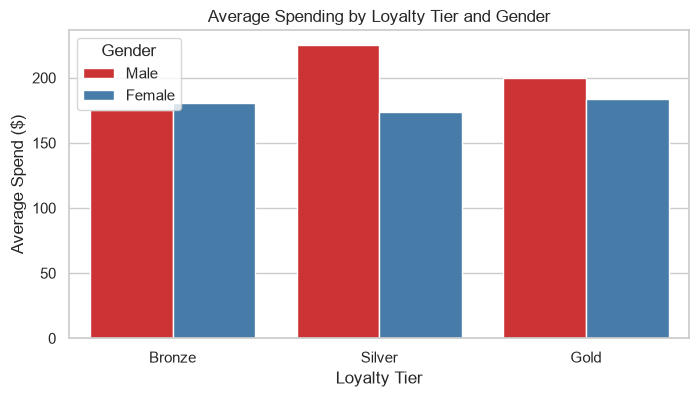

In [32]:
print("Average Spending by Loyalty Status and Gender:")
print(df_clean.groupby(['Loyalty_Status', 'Gender'])['Purchase_Amount'].agg(['mean', 'median', 'count']))


plt.figure(figsize=(8, 4))
sns.barplot(data=df_clean, x='Loyalty_Status', y='Purchase_Amount', hue='Gender', palette='Set1', order=['Bronze', 'Silver', 'Gold'], errorbar=None)
plt.title("Average Spending by Loyalty Tier and Gender")
plt.xlabel("Loyalty Tier")
plt.ylabel("Average Spend ($)")
plt.show()

### QUESTION TEN

Average Spending ($) by Age Group and Product Category:
Product_Category     Beauty    Clothing  Electronics        Home      Sports
Age_Group                                                                   
18-30             70.044444   95.405000   318.855789  284.201053  135.197667
31-45             78.434390   96.019048   322.166410  253.851111  142.128182
46-60             58.818710  111.268571   438.336071  296.192692  168.525937
60+               63.790625  101.691176   456.960833  298.357778  134.004167


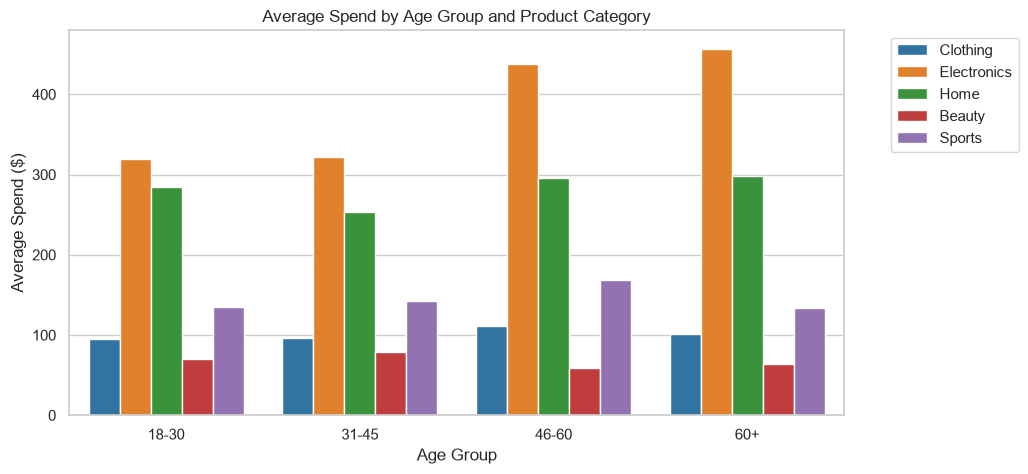

In [33]:
bins = [17, 30, 45, 60, 100]
labels = ['18-30', '31-45', '46-60', '60+']
df_clean['Age_Group'] = pd.cut(df_clean['Age'], bins=bins, labels=labels)


age_cat_spend = df_clean.groupby(['Age_Group', 'Product_Category'], observed=False)['Purchase_Amount'].mean().unstack()
print("Average Spending ($) by Age Group and Product Category:")
print(age_cat_spend)


plt.figure(figsize=(10, 5))
sns.barplot(data=df_clean, x='Age_Group', y='Purchase_Amount', hue='Product_Category', palette='tab10', errorbar=None)
plt.title("Average Spend by Age Group and Product Category")
plt.xlabel("Age Group")
plt.ylabel("Average Spend ($)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### QUESTION ELEVEN

Customer Tenure Analysis:
Mean Tenure (months) by Loyalty Tier:
Loyalty_Status
Bronze     7.166134
Gold      24.942308
Silver    16.325926
Name: Customer_Tenure, dtype: float64

Correlation between Tenure and Purchase Amount: 0.0449


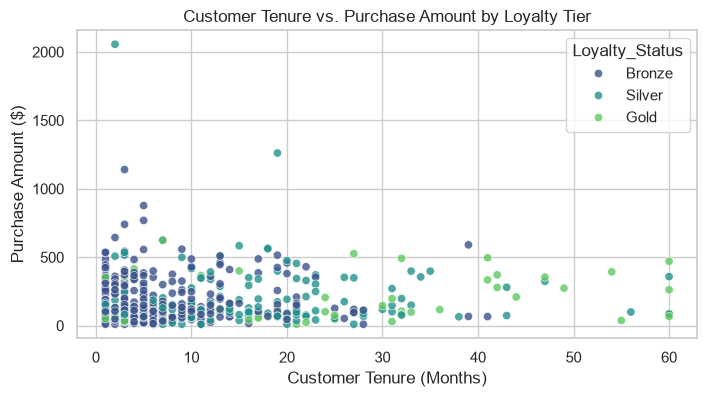

In [34]:
print("Customer Tenure Analysis:")
print("Mean Tenure (months) by Loyalty Tier:")
print(df_clean.groupby('Loyalty_Status')['Customer_Tenure'].mean())
print(f"\nCorrelation between Tenure and Purchase Amount: {df_clean['Customer_Tenure'].corr(df_clean['Purchase_Amount']):.4f}")


plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_clean, x='Customer_Tenure', y='Purchase_Amount', hue='Loyalty_Status', palette='viridis', alpha=0.8)
plt.title("Customer Tenure vs. Purchase Amount by Loyalty Tier")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Purchase Amount ($)")
plt.show()

In [ ]:
print(df.columns.tolist())

['Customer_ID', 'Age', 'Gender', 'Product_Category', 'Purchase_Amount', 'Transaction_Date', 'Customer_Tenure', 'Loyalty_Status']
